In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("jimarahman/smartphone-usage-and-addiction-analysis-dataset")

print("Path to dataset files:", path)

/home/hatch/.venvs/proyecto-integrador/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: /home/hatch/.cache/kagglehub/datasets/jimarahman/smartphone-usage-and-addiction-analysis-dataset/versions/1


# **Proyecto Daniel C. - Santiago B.**

## **Pregunta Guía:**
**¿Cómo afecta el tiempo diario de uso de dispositivos móviles a nivel de estrés y al desempeño académico de los jóvenes?**

## **Descripción del proyecto**
El proyecto busca utilizar la información de bases de datos que muestran la incidencia del consumo de dispositivos electrónicos (como celulares) en factores como el desempeño académico y la perdida de contacto con la realidad.

## **¿Cómo funcionaría?**
El programa tomaría el tiempo de consumo digital del usuario y luego le presentaría las consecuencias de aquel comportamiento basado en los datos que se dispongan; por ejemplo, si alguien usa su celular 7 horas al día, se le indicaría que ello podría causar "una disminución en la atención y un bajo rendimiento académico en un #%"

## **¿Cuál es la meta?**
La meta es concientizar a las personas sobre las consecuencias de sus hábitos de uso con respecto a la tecnología e incentivar un uso más responsable e informado.
No es lo mismo usar 5 horas el celular sabiendo que podría perder la memoria o causarse definciencias que usar el mismo tiempo un dispositivo sin conocer las consecuencias.

In [2]:
import csv
from pathlib import Path
import pandas as pd

ruta = Path("data/Smartphone_Usage_And_Addiction_Analysis_7500_Rows.csv")
if not ruta.exists():
    ruta = Path("Smartphone_Usage_And_Addiction_Analysis_7500_Rows.csv")

df = pd.read_csv(ruta)

df.head(5)

,transaction_id,user_id,age,gender,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,stress_level,academic_work_impact,addiction_level,addicted_label
0,TXN00001,U00001,21,Male,3.23,2.01,0.89,4.55,7.55,248,154,3.95,Medium,Yes,NaN,0
1,TXN00002,U00002,24,Other,5.09,3.81,2.24,4.44,7.66,127,71,6.71,Medium,Yes,NaN,0
2,TXN00003,U00003,31,Other,6.06,1.36,3.83,2.35,4.92,44,106,8.68,High,No,Mild,0
3,TXN00004,U00004,32,Other,7.83,5.85,1.51,3.54,8.23,178,107,9.77,High,Yes,Moderate,1
4,TXN00005,U00005,25,Male,9.96,5.92,3.42,5.27,6.21,136,177,12.55,Low,No,Severe,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7500 entries, 0 to 7499
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   transaction_id           7500 non-null   str    
 1   user_id                  7500 non-null   str    
 2   age                      7500 non-null   int64  
 3   gender                   7500 non-null   str    
 4   daily_screen_time_hours  7500 non-null   float64
 5   social_media_hours       7500 non-null   float64
 6   gaming_hours             7500 non-null   float64
 7   work_study_hours         7500 non-null   float64
 8   sleep_hours              7500 non-null   float64
 9   notifications_per_day    7500 non-null   int64  
 10  app_opens_per_day        7500 non-null   int64  
 11  weekend_screen_time      7500 non-null   float64
 12  stress_level             7500 non-null   str    
 13  academic_work_impact     7500 non-null   str    
 14  addiction_level          6681 non-n

El comando "df.info()" proporciona información útil como lo es el tipo de dato que constituye toda una columna, así, podemos saber qué datos son cuantificables y cuáles no.
En este caso nos interesa el número de horas que se pasa en los dispositivos

In [4]:
df.describe()

,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,addicted_label
count,7500.000000,7500.000000,7500.000000,7500.000000,7500.000000,7500.000000,7500.000000,7500.000000,7500.000000,7500.000000
mean,26.568800,7.499912,3.273484,2.014183,3.242420,6.737561,134.257333,97.832400,9.243827,0.707733
std,5.197108,2.609188,1.585342,1.146039,1.600765,1.283605,66.586883,48.423349,2.718281,0.454835
min,18.000000,3.000000,0.500000,0.000000,0.500000,4.500000,20.000000,15.000000,3.580000,0.000000
25%,22.000000,5.220000,1.910000,1.020000,1.850000,5.630000,76.000000,55.000000,6.960000,0.000000
50%,27.000000,7.525000,3.270000,2.040000,3.230000,6.720000,134.000000,98.000000,9.260000,1.000000
75%,31.000000,9.810000,4.630000,2.990000,4.640000,7.840000,191.000000,140.000000,11.540000,1.000000
max,35.000000,12.000000,6.000000,4.000000,6.000000,9.000000,250.000000,180.000000,14.880000,1.000000


Aquí vemos algunos datos que más adelante podrían sernos útiles, como lo es el promedio, el valor máximo, mínimo y aquellos que se encuentra en la mitad.
Por ejemplo, en cuanto a las horas de uso, podemos ver cuánto es el máximo en el dataset y el mínimo uso, y a su vez relacionar esto con la tabla de "adicted" que es la adicción percibida. Ya podemos ver que entre más se usa la adicción parece tener una tendencia creciente

## Limpieza de los datos

Antes de analizar, revisamos que los datos estén completos y sin errores: contamos los valores vacíos, buscamos filas duplicadas y revisamos el tipo de dato de cada columna.

Un detalle importante: en la columna `addiction_level` hay 819 valores que aparecen vacíos. En el archivo CSV original esos valores dicen "None" (que significa "sin adicción"), pero pandas los lee como valores nulos. Los dejamos como están, porque no son un error: son personas sin adicción registrada.

In [5]:
# --- Limpieza: valores nulos ---
print("Valores nulos por columna:")
print(df.isnull().sum())
print()

# Los 819 valores "None" de addiction_level (pandas los lee como nulos)
nulos_adiccion = df["addiction_level"].isnull().sum()
print("Valores 'None' (sin adicción) en addiction_level:", nulos_adiccion)
print("Total de filas del dataset:", len(df))
print()

# --- Limpieza: filas duplicadas ---
print("Filas duplicadas:", df.duplicated().sum())
print()

# --- Limpieza: tipos de datos ---
print("Tipos de datos:")
print(df.dtypes)
print()

# Decisión: no se elimina ninguna fila.
# Los 819 nulos de addiction_level significan "sin adicción" y se conservan.
# No hay duplicados, así que el dataset queda con sus 7500 filas.
print("Filas después de la limpieza:", len(df))

Valores nulos por columna:
transaction_id               0
user_id                      0
age                          0
gender                       0
daily_screen_time_hours      0
social_media_hours           0
gaming_hours                 0
work_study_hours             0
sleep_hours                  0
notifications_per_day        0
app_opens_per_day            0
weekend_screen_time          0
stress_level                 0
academic_work_impact         0
addiction_level            819
addicted_label               0
dtype: int64

Valores 'None' (sin adicción) en addiction_level: 819
Total de filas del dataset: 7500

Filas duplicadas: 0

Tipos de datos:
transaction_id                 str
user_id                        str
age                          int64
gender                         str
daily_screen_time_hours    float64
social_media_hours         float64
gaming_hours               float64
work_study_hours           float64
sleep_hours                float64
notifications_per_day  

## Estadísticas descriptivas

Además del `describe()` de arriba, calculamos las 5 estadísticas principales (media, mediana, desviación estándar, mínimo y máximo) de las horas de pantalla y de las horas de sueño. Para el estrés, que es una variable de texto (Low, Medium, High), usamos una escala numérica (Low = 1, Medium = 2, High = 3) para poder calcular sus estadísticas.

In [6]:
# --- Estadísticas de las horas de pantalla ---
pantalla = df["daily_screen_time_hours"]
print("HORAS DE PANTALLA AL DÍA")
print("Media:", round(pantalla.mean(), 2))
print("Mediana:", round(pantalla.median(), 2))
print("Desviación estándar:", round(pantalla.std(), 2))
print("Mínimo:", pantalla.min())
print("Máximo:", pantalla.max())
print()

# --- Estadísticas de las horas de sueño ---
sueno = df["sleep_hours"]
print("HORAS DE SUEÑO")
print("Media:", round(sueno.mean(), 2))
print("Mediana:", round(sueno.median(), 2))
print("Desviación estándar:", round(sueno.std(), 2))
print("Mínimo:", sueno.min())
print("Máximo:", sueno.max())
print()

# --- Estadísticas del estrés (escala: Low = 1, Medium = 2, High = 3) ---
mapa_estres = {"Low": 1, "Medium": 2, "High": 3}
estres_num = df["stress_level"].map(mapa_estres)
print("ESTRÉS (escala 1 = Low, 2 = Medium, 3 = High)")
print("Media:", round(estres_num.mean(), 2))
print("Mediana:", round(estres_num.median(), 2))
print("Desviación estándar:", round(estres_num.std(), 2))
print("Mínimo:", estres_num.min())
print("Máximo:", estres_num.max())
print()

# Distribución del estrés en porcentaje
print("Distribución del estrés:")
print((df["stress_level"].value_counts(normalize=True) * 100).round(1))
print()

# --- Cohorte de jóvenes de 18 a 25 años ---
jovenes = df[(df["age"] >= 18) & (df["age"] <= 25)]
print("COHORTE 18 A 25 AÑOS")
print("Cantidad de registros:", len(jovenes))
print("Media de horas de pantalla:", round(jovenes["daily_screen_time_hours"].mean(), 2))

HORAS DE PANTALLA AL DÍA
Media: 7.5
Mediana: 7.52
Desviación estándar: 2.61
Mínimo: 3.0
Máximo: 12.0

HORAS DE SUEÑO
Media: 6.74
Mediana: 6.72
Desviación estándar: 1.28
Mínimo: 4.5
Máximo: 9.0

ESTRÉS (escala 1 = Low, 2 = Medium, 3 = High)
Media: 2.01
Mediana: 2.0
Desviación estándar: 0.82
Mínimo: 1
Máximo: 3

Distribución del estrés:
stress_level
High      34.1
Low       33.4
Medium    32.5
Name: proportion, dtype: float64

COHORTE 18 A 25 AÑOS
Cantidad de registros: 3275
Media de horas de pantalla: 7.46


## Visualizaciones

Con tres gráficos vemos lo más importante: cómo se reparten las horas de pantalla, cómo sube la adicción cuando suben las horas, y cómo se relaciona el estrés con las horas de pantalla.

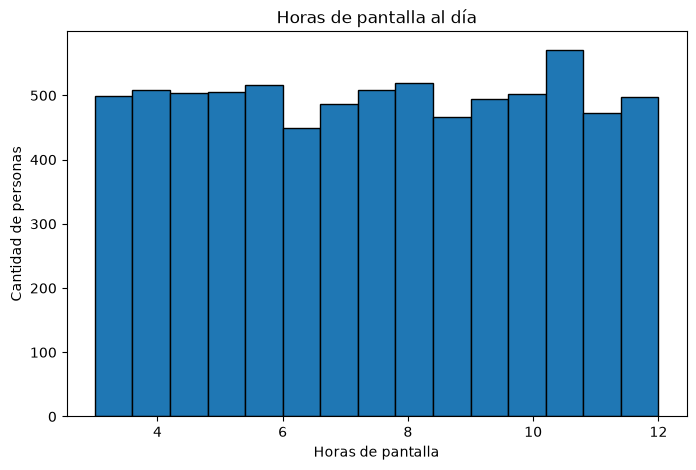

Adicción moderada/severa por tramo: [np.float64(36.2), np.float64(54.8), np.float64(100.0)]


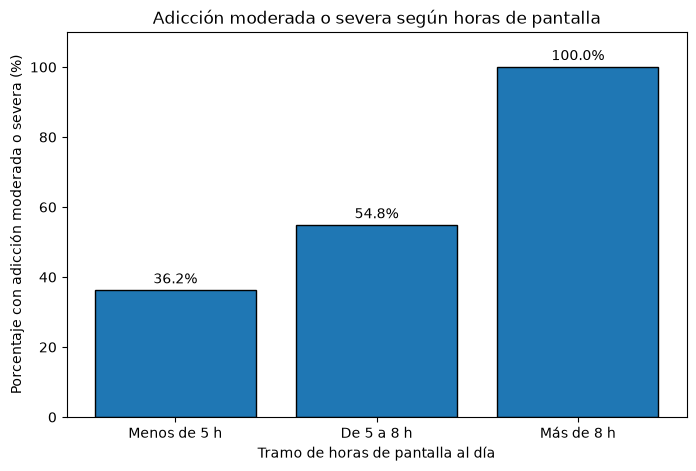

<Figure size 800x500 with 0 Axes>

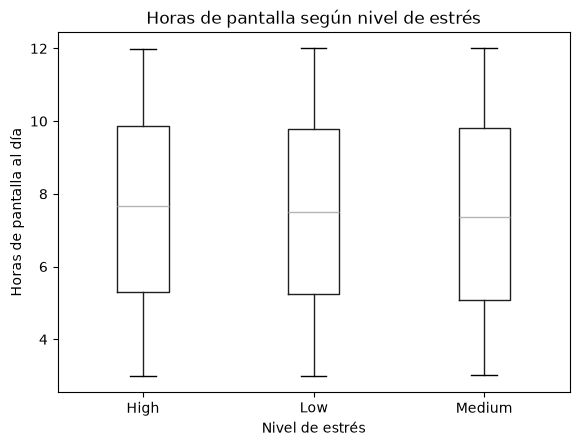

In [7]:
import matplotlib.pyplot as plt

# --- Gráfico 1: histograma de horas de pantalla ---
plt.figure(figsize=(8, 5))
plt.hist(df["daily_screen_time_hours"], bins=15, edgecolor="black")
plt.title("Horas de pantalla al día")
plt.xlabel("Horas de pantalla")
plt.ylabel("Cantidad de personas")
plt.show()

# --- Gráfico 2: adicción moderada/severa por tramo de pantalla ---
tramos = ["Menos de 5 h", "De 5 a 8 h", "Más de 8 h"]
grupos = [
    df[df["daily_screen_time_hours"] < 5],
    df[(df["daily_screen_time_hours"] >= 5) & (df["daily_screen_time_hours"] <= 8)],
    df[df["daily_screen_time_hours"] > 8],
]
porcentajes = [
    round(100 * g["addiction_level"].isin(["Moderate", "Severe"]).mean(), 1)
    for g in grupos
]
print("Adicción moderada/severa por tramo:", porcentajes)

plt.figure(figsize=(8, 5))
plt.bar(tramos, porcentajes, edgecolor="black")
plt.title("Adicción moderada o severa según horas de pantalla")
plt.xlabel("Tramo de horas de pantalla al día")
plt.ylabel("Porcentaje con adicción moderada o severa (%)")
plt.ylim(0, 110)
for i, valor in enumerate(porcentajes):
    plt.text(i, valor + 2, f"{valor}%", ha="center")
plt.show()

# --- Gráfico 3: boxplot de horas de pantalla según nivel de estrés ---
plt.figure(figsize=(8, 5))
df.boxplot(column="daily_screen_time_hours", by="stress_level", grid=False)
plt.title("Horas de pantalla según nivel de estrés")
plt.suptitle("")
plt.xlabel("Nivel de estrés")
plt.ylabel("Horas de pantalla al día")
plt.show()